# ARTI 404: Natural Language Processing — Final Project Code

## The Effect of Word Bigram Features on Sentiment Classification of Reviews Containing Negation

**Course project, Option 2 (Review Sentiment Analysis), Section 01, Group 5**  
**Team:** Joud Almutairi, Maryam Alhashim, Zhra Al Ismail

**Experimental question:** To what extent do word bigram features improve TF-IDF-based sentiment classification on reviews containing negation, compared with a unigram baseline and a pretrained Sentence-BERT approach?

| Section | Content |
| :--- | :--- |
| **1. Setup** | Dependencies, random seed, output directories |
| **2. Data** | Loading, cleaning, 70/15/15 split, split check, negation filtering and audit, shared evaluation utilities |
| **3. Method 1** | TF-IDF + Logistic Regression: unigram baseline and unigram + bigram features |
| **4. Method 2** | Sentence-BERT (`all-MiniLM-L6-v2`) + Logistic Regression |
| **5. Results** | Validation checks, test evaluation, summary table, unigram vs. bigram comparison, error analysis |
| **6. Try it** | Inference on custom reviews using saved models, including team sample inputs |
| **7. Sources** | Dataset, libraries, pretrained models, AI disclosure |

**Figures:** Plots (Figures 1–8) are generated from model outputs and saved to `results/figures/` for use in the report and slides.

## 1. Setup
Install required packages, import libraries, set the random seed, and create output folders.

In [40]:
%pip install -q sentence-transformers scikit-learn pandas numpy

In [41]:
import os, io, re, random, zipfile, hashlib, urllib.request
from itertools import product

import numpy as np
import pandas as pd
import sklearn
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, f1_score, classification_report

SEED = 42                       # one seed everywhere for reproducibility
random.seed(SEED)
np.random.seed(SEED)

DATA_DIR = "data"               # relative paths only
RESULTS_DIR = "results"
os.makedirs(DATA_DIR, exist_ok=True)
os.makedirs(RESULTS_DIR, exist_ok=True)
pd.set_option("display.max_colwidth", 160)
pd.set_option("display.width", 200)

# Record package versions (copy these into the report and requirements.txt)
print("numpy       :", np.__version__)
print("pandas      :", pd.__version__)
print("scikit-learn:", sklearn.__version__)
try:
    import sentence_transformers
    print("sentence-transformers:", sentence_transformers.__version__)
except ImportError:
    print("sentence-transformers not installed (needed for Method 2)")

numpy       : 2.4.6
pandas      : 2.2.3
scikit-learn: 1.6.1
sentence-transformers: 5.7.0


### Figure settings
Configure plot styling, shared color palettes, and helper functions (`save_fig`, `annotate_bars`, `metrics_frame`, and `grouped_metric_chart`) to display, save, and format evaluation charts consistently.

In [42]:
import textwrap
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from sklearn.metrics import confusion_matrix

FIG_DIR = os.path.join(RESULTS_DIR, "figures")
os.makedirs(FIG_DIR, exist_ok=True)

plt.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white", "savefig.facecolor": "white",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.grid.axis": "y", "grid.alpha": 0.3, "axes.axisbelow": True,
    "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold",
})

LABEL_COLORS = {"Negative": "#d1495b", "Positive": "#00798c"}        # sentiment classes
METRIC_COLORS = {"Accuracy": "#3d5a80", "Macro F1": "#ee9b00"}       # evaluation metrics
SOURCE_LABELS = {"amazon": "Amazon", "imdb": "IMDb", "yelp": "Yelp"}
LABEL_NAMES = {0: "Negative", 1: "Positive"}                           # same mapping used again in Section 2.5

def save_fig(fig, name):
    """Show the figure and save it to results/figures/<name>.png."""
    fig.savefig(os.path.join(FIG_DIR, name + ".png"), dpi=200, bbox_inches="tight")
    plt.show()

def annotate_bars(ax, fmt="{:.0f}", fontsize=9):
    """Write the value above every bar."""
    for container in ax.containers:
        ax.bar_label(container, labels=[fmt.format(v) for v in container.datavalues], padding=2, fontsize=fontsize)
    ax.margins(y=0.14)

def metrics_frame(scope):
    """Accuracy and macro F1 per model, taken directly from RESULTS (scope: 'full' or 'neg')."""
    return pd.DataFrame({m: {"Accuracy": r[scope]["accuracy"], "Macro F1": r[scope]["macro_f1"]}
                         for m, r in RESULTS.items()}).T

def grouped_metric_chart(ax, frame, title):
    """Grouped bars: one group per model, one bar per metric."""
    x, width = np.arange(len(frame)), 0.38
    for offset, metric in zip((-width / 2, width / 2), ("Accuracy", "Macro F1")):
        ax.bar(x + offset, frame[metric], width, label=metric, color=METRIC_COLORS[metric])
    ax.set_xticks(x)
    ax.set_xticklabels([textwrap.fill(m, 16) for m in frame.index])
    ax.set_ylim(0, 1.2)
    ax.set_yticks(np.arange(0, 1.01, 0.2))
    ax.set_ylabel("Score")
    ax.set_title(title)
    annotate_bars(ax, fmt="{:.3f}", fontsize=8.5)
    ax.set_ylim(0, 1.2)
    ax.legend(frameon=False, loc="upper left", ncol=2)

## 2. Data
**Dataset:** UCI Sentiment Labelled Sentences (Amazon, IMDb, Yelp; label 1 = Positive, 0 = Negative).

### 2.1 Load

We downloaded and extracted the UCI dataset, loaded and combined the three source files (`quoting=3` treats quotes as literal characters), removed missing rows, formatted text and integer labels, and displayed class counts per source.

In [43]:
DATA_URL = "https://archive.ics.uci.edu/static/public/331/sentiment+labelled+sentences.zip"
SOURCE_FILES = {
    "amazon": "amazon_cells_labelled.txt",
    "imdb":   "imdb_labelled.txt",
    "yelp":   "yelp_labelled.txt",
}

def find_file(name, root):
    """Search for a file under root (the zip may extract into a sub-folder)."""
    for dirpath, _, files in os.walk(root):
        if name in files:
            return os.path.join(dirpath, name)
    return None

def ensure_dataset():
    """Download and extract the dataset only if it is not already in DATA_DIR."""
    if all(find_file(f, DATA_DIR) for f in SOURCE_FILES.values()):
        print("Dataset already present.")
        return
    print("Downloading dataset from UCI ...")
    raw = urllib.request.urlopen(DATA_URL, timeout=60).read()
    zipfile.ZipFile(io.BytesIO(raw)).extractall(DATA_DIR)
    print("Done.")

ensure_dataset()

frames = []
for source, filename in SOURCE_FILES.items():
    path = find_file(filename, DATA_DIR)
    part = pd.read_csv(path, sep="\t", header=None, names=["text", "label"],
                       quoting=3, encoding="utf-8-sig")   # quoting=3: quotes are plain characters
    part["source"] = source
    frames.append(part)

raw_df = pd.concat(frames, ignore_index=True)
n_loaded = len(raw_df)
raw_df = raw_df.dropna(subset=["text", "label"]).copy()
print(f"Rows loaded: {n_loaded} | rows dropped for missing text/label: {n_loaded - len(raw_df)}")
raw_df["label"] = raw_df["label"].astype(int)
raw_df["text"] = raw_df["text"].astype(str).str.strip()

print("\nRaw class counts per source (UCI documents 500 positive + 500 negative per source):")
display(raw_df.groupby(["source", "label"]).size().unstack(fill_value=0))

Dataset already present.
Rows loaded: 3000 | rows dropped for missing text/label: 0

Raw class counts per source (UCI documents 500 positive + 500 negative per source):


label,0,1
source,,
amazon,500,500
imdb,500,500
yelp,500,500


### 2.2 Clean
We kept the original review text unchanged (no stop-word removal or stemming) so negation words remain intact. Using a lowercase, whitespace-normalized copy, we dropped duplicates with conflicting labels and kept the first occurrence of clean duplicates.

In [44]:
raw_df["norm"] = raw_df["text"].str.lower().str.replace(r"\s+", " ", regex=True)

dup_rows = raw_df[raw_df.duplicated("norm", keep=False)]
label_conflicts = dup_rows.groupby("norm")["label"].nunique()
conflicting_keys = set(label_conflicts[label_conflicts > 1].index)

print("Rows involved in duplicates              :", len(dup_rows))
print("Duplicate texts with conflicting labels  :", len(conflicting_keys))

df = raw_df[~raw_df["norm"].isin(conflicting_keys)]
df = df.drop_duplicates("norm", keep="first").reset_index(drop=True)

print("Size before cleaning:", len(raw_df), "| after cleaning:", len(df))
display(df.groupby(["source", "label"]).size().unstack(fill_value=0))

Rows involved in duplicates              : 40
Duplicate texts with conflicting labels  : 0
Size before cleaning: 3000 | after cleaning: 2979


label,0,1
source,,
amazon,496,491
imdb,498,498
yelp,497,499


#### Dataset distribution
Figure 1 shows the cleaned class counts per source so we can check rough class balance and confirm no source dominates.

,Negative,Positive,Total
Source,,,
Amazon,496,491,987
IMDb,498,498,996
Yelp,497,499,996


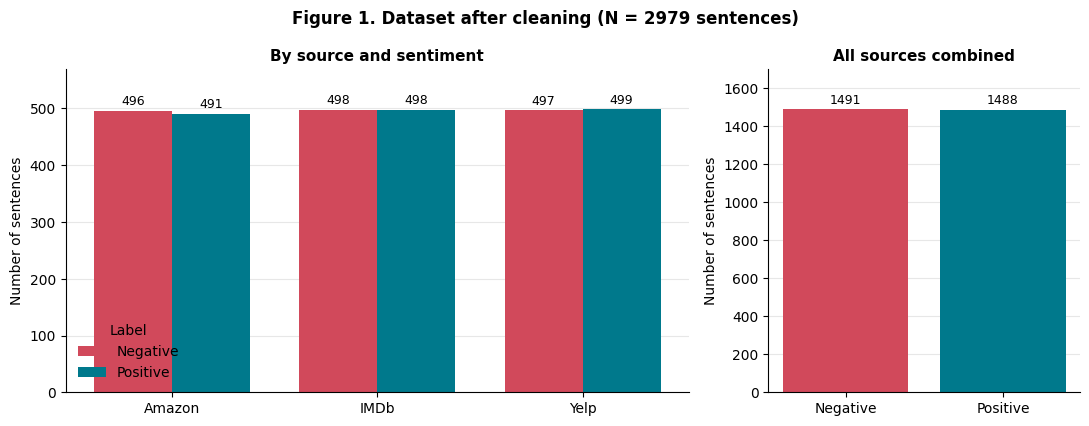

Positive share of the cleaned dataset: 49.9%


In [45]:
source_order = ["amazon", "imdb", "yelp"]

counts = df.groupby(["source", "label"]).size().unstack(fill_value=0).reindex(source_order)

counts.columns = [LABEL_NAMES[c] for c in counts.columns]
counts["Total"] = counts.sum(axis=1)

display(counts.rename(index=SOURCE_LABELS).rename_axis("Source"))

fig, (ax1, ax2) = plt.subplots(
    1, 2, figsize=(11, 4.3),
    gridspec_kw={"width_ratios": [2, 1]}
)

x, width = np.arange(len(source_order)), 0.38

for offset, lab in zip((-width / 2, width / 2), ("Negative", "Positive")):
    ax1.bar(x + offset, counts[lab], width, label=lab, color=LABEL_COLORS[lab])

ax1.set_xticks(x)
ax1.set_xticklabels([SOURCE_LABELS[s] for s in source_order])
ax1.set_ylabel("Number of sentences")
ax1.set_title("By source and sentiment")
annotate_bars(ax1)
ax1.legend(title="Label", frameon=False)

overall = counts[["Negative", "Positive"]].sum()

ax2.bar(overall.index, overall.values, color=[LABEL_COLORS[l] for l in overall.index])
ax2.set_ylabel("Number of sentences")
ax2.set_title("All sources combined")
annotate_bars(ax2)

fig.suptitle(
    f"Figure 1. Dataset after cleaning (N = {len(df)} sentences)",
    fontweight="bold"
)

fig.tight_layout()
save_fig(fig, "fig1_dataset_distribution")

print(f"Positive share of the cleaned dataset: {overall['Positive'] / overall.sum():.1%}")

Each source contributes a similar volume of reviews with near-balanced classes, so accuracy and macro F1 should stay close on the full test set but may diverge more on the negation subset if class balance shifts.

### 2.3 Split 70 / 15 / 15
We split the dataset once using a fixed seed and stratified sampling on **sentiment label and source domain combined** (six strata). Removing duplicates beforehand prevents cross-split leakage, and all three models use the exact same `train_df`, `dev_df`, and `test_df`.

In [46]:
df["strata"] = df["source"] + "_" + df["label"].astype(str)

def make_split(data, seed=SEED):
    """70% train, 15% dev, 15% test; stratified on source + label."""
    train, temp = train_test_split(data, test_size=0.30, stratify=data["strata"], random_state=seed)
    dev, test = train_test_split(temp, test_size=0.50, stratify=temp["strata"], random_state=seed)
    return train, dev, test

train_df, dev_df, test_df = [d.reset_index(drop=True) for d in make_split(df)]

def split_hash(d):
    """Short fingerprint of a split, used to prove all models saw identical data."""
    return hashlib.md5("\n".join(d["text"]).encode("utf-8")).hexdigest()[:10]

SPLITS = {"train": train_df, "dev": dev_df, "test": test_df}
print({name: (len(d), split_hash(d)) for name, d in SPLITS.items()})

{'train': (2085, 'a1f1576783'), 'dev': (447, '296e5af447'), 'test': (447, '7d254cafd3')}


### 2.4 Verify the split
We checked split proportions, stratum shares (`label` × `source`), and zero overlap across splits, then saved the assignments to `results/split_assignment.csv`.

In [47]:
total = len(df)
targets = {"train": 0.70, "dev": 0.15, "test": 0.15}

size_rows = []
for name, d in SPLITS.items():
    size_rows.append({"split": name, "n": len(d), "share": f"{len(d) / total:.1%}", "target": f"{targets[name]:.0%}"})
    assert abs(len(d) / total - targets[name]) < 0.005, f"{name} size is off target"
display(pd.DataFrame(size_rows))

# Share of each source x label stratum inside every split vs. in the whole dataset
overall_share = df["strata"].value_counts(normalize=True)
share_table = pd.concat(
    [overall_share.rename("overall")] +
    [d["strata"].value_counts(normalize=True).reindex(overall_share.index, fill_value=0).rename(n)
     for n, d in SPLITS.items()], axis=1)
display((share_table * 100).round(1))
max_dev = max((share_table[n] - share_table["overall"]).abs().max() for n in SPLITS)
print(f"Largest deviation of a stratum share from the overall share: {max_dev * 100:.2f} percentage points")
assert max_dev < 0.01, "split is not stratified on source and label"

# Counts per split
display(pd.concat({n: d.groupby(["source", "label"]).size().unstack(fill_value=0) for n, d in SPLITS.items()}, axis=1))

# No sentence appears in more than one split
for a, b in [("train", "dev"), ("train", "test"), ("dev", "test")]:
    assert not set(SPLITS[a]["norm"]) & set(SPLITS[b]["norm"]), f"{a}/{b} overlap"
print("No overlap between train, dev and test.")

pd.concat([d.assign(split=n)[["split", "source", "label", "text"]] for n, d in SPLITS.items()]
          ).to_csv(os.path.join(RESULTS_DIR, "split_assignment.csv"), index=False)

,split,n,share,target
0,train,2085,70.0%,70%
1,dev,447,15.0%,15%
2,test,447,15.0%,15%


,overall,train,dev,test
strata,,,,
yelp_1,16.8,16.7,16.8,16.8
imdb_0,16.7,16.7,16.8,16.8
imdb_1,16.7,16.7,16.6,16.8
yelp_0,16.7,16.7,16.8,16.6
amazon_0,16.6,16.6,16.6,16.8
amazon_1,16.5,16.5,16.6,16.3


Largest deviation of a stratum share from the overall share: 0.16 percentage points


train      dev     test    
label      0    1   0   1    0   1
source                            
amazon   347  344  74  74   75  73
imdb     348  349  75  74   75  75
yelp     348  349  75  75   74  75

No overlap between train, dev and test.


#### Split distribution
Figure 2 shows the 70 / 15 / 15 split proportions on the left and class balance across splits on the right to confirm the stratified split.

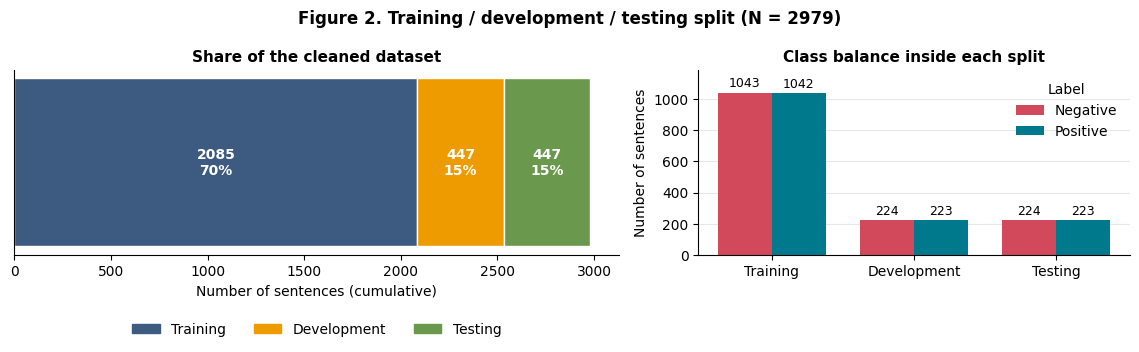

In [48]:
split_names = {"train": "Training", "dev": "Development", "test": "Testing"}
split_colors = {"train": "#3d5a80", "dev": "#ee9b00", "test": "#6a994e"}

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11.5, 3.9), gridspec_kw={"width_ratios": [1.4, 1]})
start = 0
for key, d in SPLITS.items():
    ax1.barh(0, len(d), left=start, height=0.6, color=split_colors[key], edgecolor="white")
    ax1.text(start + len(d) / 2, 0, f"{len(d)}\n{len(d) / total:.0%}", ha="center", va="center",
             color="white", fontweight="bold")
    start += len(d)
ax1.set_yticks([])
ax1.set_xlabel("Number of sentences (cumulative)")
ax1.set_title("Share of the cleaned dataset")
ax1.grid(False)
ax1.legend(handles=[Patch(color=split_colors[k], label=split_names[k]) for k in SPLITS],
           loc="upper center", bbox_to_anchor=(0.5, -0.3), ncol=3, frameon=False)

label_counts = pd.DataFrame({split_names[k]: d["label"].map(LABEL_NAMES).value_counts() for k, d in SPLITS.items()}).T
x, width = np.arange(len(label_counts)), 0.38
for offset, lab in zip((-width / 2, width / 2), ("Negative", "Positive")):
    ax2.bar(x + offset, label_counts[lab], width, label=lab, color=LABEL_COLORS[lab])
ax2.set_xticks(x)
ax2.set_xticklabels(label_counts.index)
ax2.set_ylabel("Number of sentences")
ax2.set_title("Class balance inside each split")
annotate_bars(ax2)
ax2.legend(title="Label", frameon=False)

fig.suptitle(f"Figure 2. Training / development / testing split (N = {total})", fontweight="bold")
fig.tight_layout()
save_fig(fig, "fig2_split_distribution")

All three splits match the 70 / 15 / 15 target with consistent class balance. We use `train` to fit models, `dev` to tune settings, and `test` strictly for final evaluation.

### 2.5 Negation filter
We flag a review as negation-related if it contains at least one whole-word, case-insensitive match from the proposal list (`not`, `never`, `no`). Contractions such as *don't* are excluded by default (`INCLUDE_CONTRACTIONS = False`), and matched terms are recorded for subset inspection.

In [49]:
NEGATION_TERMS = ["not", "never", "no"]          # predefined list from the proposal
INCLUDE_CONTRACTIONS = False                     # True would also match n't (e.g. "wasn't")
LABEL_NAMES = {0: "Negative", 1: "Positive"}

def build_matcher(terms, contractions=False, substring=False):
    """Compile a negation matcher. substring=True is only used in the audit to show over-matching."""
    body = "|".join(re.escape(t) for t in terms)
    pat = body if substring else r"\b(?:" + body + r")\b"
    if contractions:
        pat += r"|\b\w+n['\u2019]t\b"
    return re.compile(pat, re.IGNORECASE)

NEGATION_PATTERN = build_matcher(NEGATION_TERMS, INCLUDE_CONTRACTIONS)

def matched_terms(text, pattern=NEGATION_PATTERN):
    return sorted({m.group(0).lower() for m in pattern.finditer(text)})

def has_negation(text, pattern=NEGATION_PATTERN):
    return bool(pattern.search(text))

for d in (train_df, dev_df, test_df, df):
    d["negation_terms"] = d["text"].apply(matched_terms)
    d["negation"] = d["negation_terms"].str.len() > 0

def class_counts(d):
    c = d["label"].value_counts().reindex([1, 0], fill_value=0)
    return len(d), int(c[1]), int(c[0])

def describe_split(name, d):
    n, p, q = class_counts(d)
    print(f"{name:<24} n={n:>4} | Positive={p:>4} | Negative={q:>4} | Positive share={p / max(n, 1):.1%}")

print("Class distribution")
describe_split("Train", train_df)
describe_split("Dev", dev_df)
describe_split("Test (full)", test_df)
describe_split("Test (negation subset)", test_df[test_df["negation"]])
print("\nShare of negation-related reviews:",
      {n: f"{d['negation'].mean():.1%}" for n, d in SPLITS.items()})

print("\nNegation terms in the test negation subset (a review can contain several):")
print(test_df[test_df["negation"]]["negation_terms"].explode().value_counts().to_string())

Class distribution
Train                    n=2085 | Positive=1042 | Negative=1043 | Positive share=50.0%
Dev                      n= 447 | Positive= 223 | Negative= 224 | Positive share=49.9%
Test (full)              n= 447 | Positive= 223 | Negative= 224 | Positive share=49.9%
Test (negation subset)   n=  51 | Positive=   9 | Negative=  42 | Positive share=17.6%

Share of negation-related reviews: {'train': '13.8%', 'dev': '14.5%', 'test': '11.4%'}

Negation terms in the test negation subset (a review can contain several):
negation_terms
not      36
no       12
never     5


### 2.6 Negation Subset Audit

The original proposal reported 55 negation-related test reviews (14 positive and 41 negative). In the final implementation, the number differs because the dataset was cleaned by removing exact duplicates before splitting. In addition, the 70/15/15 split was stratified by source and sentiment label, not by negation. Therefore, the number of negation-related reviews in the test set was not fixed.

We report the actual negation subset counts obtained from the final implementation and use the same subset and negation definition to evaluate all models. This section also provides an audit of the cleaning process and the resulting counts.

#### Cleaning audit: what was removed, and how many negation reviews it affected

In [50]:
# Row counts at each cleaning step
n_original = n_loaded                                                   # rows read from the three UCI files
n_missing = n_loaded - len(raw_df)                                      # rows dropped for a missing text or label
n_conflict_rows = int(raw_df["norm"].isin(conflicting_keys).sum())      # every copy of a text with conflicting labels
n_duplicate_removed = len(raw_df) - n_conflict_rows - len(df)           # extra copies of repeated texts (one copy kept)

assert n_original - n_missing - n_conflict_rows - n_duplicate_removed == len(df)    # the steps add up to the final size
assert len(train_df) + len(dev_df) + len(test_df) == len(df)                        # the three splits cover the cleaned data

cleaning_audit = pd.DataFrame([
    ("Original dataset (rows read from the three files)", n_original),
    ("Rows dropped for missing text or label", n_missing),
    ("Duplicate rows removed (extra copies, one copy kept)", n_duplicate_removed),
    ("Rows removed because copies had conflicting labels", n_conflict_rows),
    ("Final cleaned dataset", len(df)),
], columns=["Step", "Rows"])
display(cleaning_audit)

# Negation-related reviews before and after cleaning (same pattern as Section 2.5)
raw_flags = raw_df["text"].apply(has_negation)
clean_flags = df["text"].apply(has_negation)
assert int(clean_flags.sum()) == int(df["negation"].sum())              # identical to the flags used for the splits

def neg_row(frame, flags):
    sub = frame[flags]
    return len(sub), int((sub["label"] == 1).sum()), int((sub["label"] == 0).sum())

raw_row, clean_row = neg_row(raw_df, raw_flags), neg_row(df, clean_flags)
removed_row = tuple(a - b for a, b in zip(raw_row, clean_row))
negation_audit = pd.DataFrame(
    [("Raw data (after loading, before duplicate removal)",) + raw_row,
     ("Cleaned data",) + clean_row,
     ("Removed by cleaning",) + removed_row],
    columns=["Dataset", "Negation-related reviews", "Positive", "Negative"])
display(negation_audit)
print(f"For scale: a 15% test share of the {removed_row[0]} negation-related reviews removed by cleaning is about "
      f"{0.15 * removed_row[0]:.1f} reviews (an expectation, not a measured effect).")

cleaning_audit.to_csv(os.path.join(RESULTS_DIR, "cleaning_audit.csv"), index=False)
negation_audit.to_csv(os.path.join(RESULTS_DIR, "cleaning_audit_negation.csv"), index=False)

,Step,Rows
0,Original dataset (rows read from the three files),3000
1,Rows dropped for missing text or label,0
2,"Duplicate rows removed (extra copies, one copy kept)",21
3,Rows removed because copies had conflicting labels,0
4,Final cleaned dataset,2979


,Dataset,Negation-related reviews,Positive,Negative
0,"Raw data (after loading, before duplicate removal)",407,86,321
1,Cleaned data,404,86,318
2,Removed by cleaning,3,0,3


For scale: a 15% test share of the 3 negation-related reviews removed by cleaning is about 0.4 reviews (an expectation, not a measured effect).


In [51]:
PROPOSAL_REPORTED = (55, 14, 41)    # (n, positive, negative) as written in the proposal; reference only
observed = class_counts(test_df[test_df["negation"]])
print(f"Observed in this notebook (seed {SEED}): n={observed[0]}, positive={observed[1]}, negative={observed[2]}")
print(f"Proposal reported                    : n={PROPOSAL_REPORTED[0]}, positive={PROPOSAL_REPORTED[1]}, negative={PROPOSAL_REPORTED[2]}")

# (a) How many negation reviews exist in the whole cleaned dataset, and what 15% of them would be
all_neg = df[df["negation"]]
n_all, p_all, q_all = class_counts(all_neg)
print(f"\n(a) Whole cleaned dataset: {n_all} negation reviews ({p_all} positive, {q_all} negative). "
      f"A 15% test split is expected to hold about {0.15 * n_all:.0f} ({0.15 * p_all:.0f} positive, {0.15 * q_all:.0f} negative).")

# (b) Same seed, other plausible definitions or cleaning choices
def subset_for(data, pattern, seed=SEED):
    d = data.copy()
    d["strata"] = d["source"] + "_" + d["label"].astype(str)
    te = make_split(d, seed)[2]
    sub = te[te["text"].apply(lambda t: has_negation(t, pattern))]
    return (len(te),) + class_counts(sub)

variants = {
    "Current: cleaned, not/never/no, whole word":           (df,     NEGATION_PATTERN),
    "Same list + contractions (don't, wasn't ...)":        (df,     build_matcher(NEGATION_TERMS, True)),
    "Extended list (+nothing, none, nobody, neither, nor, cannot)": (df, build_matcher(NEGATION_TERMS + ["nothing", "none", "nobody", "neither", "nor", "cannot"])),
    "Substring match (over-matches: know, note, now ...)": (df,     build_matcher(NEGATION_TERMS, substring=True)),
    "No duplicate removal (raw 3000 rows)":                (raw_df, NEGATION_PATTERN),
}
audit = pd.DataFrame(
    [(k,) + subset_for(*v) for k, v in variants.items()],
    columns=["Variant (seed 42)", "Test size", "Negation n", "Positive", "Negative"])
print("\n(b) Effect of the negation definition and of cleaning on the test subset:")
display(audit)

# (c) Effect of the random seed (same cleaned data, same procedure)
sweep = []
for s in range(100):
    te = make_split(df, s)[2]
    sweep.append(class_counts(te[te["negation"]]))
sweep = pd.DataFrame(sweep, columns=["n", "pos", "neg"])
hits = int(((sweep["n"] == PROPOSAL_REPORTED[0]) & (sweep["pos"] == PROPOSAL_REPORTED[1]) &
            (sweep["neg"] == PROPOSAL_REPORTED[2])).sum())
print("\n(c) Same procedure, 100 different seeds (diagnostic only; the experiment keeps seed 42):")
display(sweep.describe().loc[["min", "mean", "max"]].round(1))
print(f"Seeds that give exactly {PROPOSAL_REPORTED}: {hits} of 100")

Observed in this notebook (seed 42): n=51, positive=9, negative=42
Proposal reported                    : n=55, positive=14, negative=41

(a) Whole cleaned dataset: 404 negation reviews (86 positive, 318 negative). A 15% test split is expected to hold about 61 (13 positive, 48 negative).

(b) Effect of the negation definition and of cleaning on the test subset:


,Variant (seed 42),Test size,Negation n,Positive,Negative
0,"Current: cleaned, not/never/no, whole word",447,51,9,42
1,"Same list + contractions (don't, wasn't ...)",447,87,18,69
2,"Extended list (+nothing, none, nobody, neither, nor, cannot)",447,59,10,49
3,"Substring match (over-matches: know, note, now ...)",447,85,21,64
4,No duplicate removal (raw 3000 rows),450,54,9,45



(c) Same procedure, 100 different seeds (diagnostic only; the experiment keeps seed 42):


,n,pos,neg
min,42.0,6.0,32.0
mean,59.5,12.1,47.4
max,76.0,20.0,62.0


Seeds that give exactly (55, 14, 41): 1 of 100


In [52]:
print("AUDIT SUMMARY (generated from the numbers above)")
print(f"- With the specified procedure the reproducible test subset is n={observed[0]} "
      f"({observed[1]} positive, {observed[2]} negative); the proposal says {PROPOSAL_REPORTED}.")
print("- The subset size depends on the seed, on duplicate removal and on the negation definition, "
      "because the split is not stratified on negation.")
print(f"- Across 100 seeds the size ranges from {int(sweep['n'].min())} to {int(sweep['n'].max())} "
      f"and the positive count from {int(sweep['pos'].min())} to {int(sweep['pos'].max())}.")
print("- No examples were added, removed or moved to match the proposal. "
      "The observed counts are the ones used in all results below. "
      "The instructor has confirmed that the final report may differ from the proposal when the difference is explained.")

AUDIT SUMMARY (generated from the numbers above)
- With the specified procedure the reproducible test subset is n=51 (9 positive, 42 negative); the proposal says (55, 14, 41).
- The subset size depends on the seed, on duplicate removal and on the negation definition, because the split is not stratified on negation.
- Across 100 seeds the size ranges from 42 to 76 and the positive count from 6 to 20.
- No examples were added, removed or moved to match the proposal. The observed counts are the ones used in all results below. The instructor has confirmed that the final report may differ from the proposal when the difference is explained.



Three sentiment classification models are trained and compared:

1. TF-IDF Unigram + Logistic Regression
2. TF-IDF Unigram + Bigram + Logistic Regression
3. Sentence-BERT (SBERT) + Logistic Regression

The models are trained using the training set, while hyperparameters are tuned using the development set based on Macro F1. After selecting the best settings, each model is evaluated on the same held-out test set.

Performance is measured using Accuracy and Macro F1 on both the full test set and the negation subset. The test set is kept separate during training and hyperparameter tuning to ensure a fair evaluation.

In [53]:
NAME_UNI, NAME_BI, NAME_SBERT = "TF-IDF unigram + LR", "TF-IDF uni+bigram + LR", "SBERT + LR"

def evaluate_predictions(y_true, y_pred):
    """Accuracy and macro F1 (each class weighted equally)."""
    return {
        "n": int(len(y_true)),
        "accuracy": accuracy_score(y_true, y_pred),
        "macro_f1": f1_score(y_true, y_pred, average="macro", labels=[0, 1], zero_division=0),
    }

def evaluate_model(model, d):
    """Metrics on the full set d and on its negation subset, plus the predictions."""
    y = d["label"].to_numpy()
    preds = np.asarray(model.predict(d["text"].tolist()))
    mask = d["negation"].to_numpy()
    return evaluate_predictions(y, preds), evaluate_predictions(y[mask], preds[mask]), preds

MODELS, RESULTS, TEST_PREDS, FIT_LOG = {}, {}, {}, {}

def tune_on_dev(name, make_model, param_grid, train_d, dev_d):
    """Fit on TRAIN only and pick the setting with the best DEV macro F1. The test set is never used here."""
    assert split_hash(dev_d) != split_hash(test_df), "tuning must not use the test set"
    assert split_hash(train_d) != split_hash(test_df), "training must not use the test set"
    keys, best, log = list(param_grid), None, []
    for values in product(*param_grid.values()):
        params = dict(zip(keys, values))
        model = make_model(**params)
        model.fit(train_d["text"].tolist(), train_d["label"].to_numpy())
        dev_f1 = f1_score(dev_d["label"].to_numpy(), model.predict(dev_d["text"].tolist()),
                          average="macro", labels=[0, 1], zero_division=0)
        log.append({**params, "dev_macro_f1": dev_f1})
        if best is None or dev_f1 > best[0]:
            best = (dev_f1, params, model)
    FIT_LOG[name] = {"train": split_hash(train_d), "dev": split_hash(dev_d), "params": best[1]}
    MODELS[name] = best[2]
    log_df = pd.DataFrame(log).sort_values("dev_macro_f1", ascending=False).reset_index(drop=True)
    return best[2], best[1], log_df

def final_test(name):
    """Evaluate one tuned model on the held-out test set (called once per model)."""
    full, neg, preds = evaluate_model(MODELS[name], test_df)
    RESULTS[name] = {"full": full, "neg": neg}
    TEST_PREDS[name] = preds
    FIT_LOG[name]["test"] = split_hash(test_df)
    print(f"{name}: full acc={full['accuracy']:.3f}, macro F1={full['macro_f1']:.3f} | "
          f"negation acc={neg['accuracy']:.3f}, macro F1={neg['macro_f1']:.3f} (n={neg['n']})")

## 3. Method 1: TF-IDF + Logistic Regression

We implemented two TF-IDF variants using the same pipeline and C grid, with the only difference being the n-gram range. The vectorizer was fitted on training data only. We kept `stop_words=None` to preserve negation words such as *not* and *no*.

In [54]:
def make_tfidf_lr(ngram_range=(1, 1), C=1.0):
    return Pipeline([
        ("tfidf", TfidfVectorizer(lowercase=True, ngram_range=ngram_range, stop_words=None)),
        ("clf", LogisticRegression(C=C, max_iter=1000, random_state=SEED)),
    ])

C_GRID = [0.1, 1, 10, 100]

###  Model 1: unigrams (baseline)

In [55]:
model_uni, params_uni, log_uni = tune_on_dev(
    NAME_UNI, make_tfidf_lr, {"ngram_range": [(1, 1)], "C": C_GRID}, train_df, dev_df)
print("Best settings (chosen on the development set):", params_uni)
display(log_uni)

Best settings (chosen on the development set): {'ngram_range': (1, 1), 'C': 10}


,ngram_range,C,dev_macro_f1
0,"(1, 1)",10.0,0.843268
1,"(1, 1)",100.0,0.838693
2,"(1, 1)",1.0,0.815979
3,"(1, 1)",0.1,0.800895


###  Model 2: unigrams + bigrams

In [56]:
model_bi, params_bi, log_bi = tune_on_dev(
    NAME_BI, make_tfidf_lr, {"ngram_range": [(1, 2)], "C": C_GRID}, train_df, dev_df)
print("Best settings (chosen on the development set):", params_bi)
display(log_bi)

Best settings (chosen on the development set): {'ngram_range': (1, 2), 'C': 10}


,ngram_range,C,dev_macro_f1
0,"(1, 2)",100.0,0.811808
1,"(1, 2)",10.0,0.811808
2,"(1, 2)",1.0,0.809382
3,"(1, 2)",0.1,0.787404


## 4.Method 2: Sentence-BERT + Logistic Regression

We used the pretrained `all-MiniLM-L6-v2` encoder without fine-tuning to convert reviews into vectors. We trained Logistic Regression on the training embeddings only and cached the embeddings to avoid repeated encoding during tuning.

In [57]:
from sentence_transformers import SentenceTransformer

SBERT_NAME = "sentence-transformers/all-MiniLM-L6-v2"
encoder = SentenceTransformer(SBERT_NAME)          # existing pretrained weights, not trained here

class SBERTLogReg:
    """Sentence-BERT embeddings + Logistic Regression, with the same fit/predict interface as the TF-IDF pipelines."""
    _cache = {}                                    # shared embedding cache: (model name, text) -> vector

    def __init__(self, encoder, model_name, C=1.0):
        self.encoder, self.model_name, self.C = encoder, model_name, C
        self.clf = LogisticRegression(C=C, max_iter=1000, random_state=SEED)

    def _embed(self, texts):
        missing = [t for t in dict.fromkeys(texts) if (self.model_name, t) not in self._cache]
        if missing:
            vectors = self.encoder.encode(missing, batch_size=64, show_progress_bar=False)
            for t, v in zip(missing, vectors):
                self._cache[(self.model_name, t)] = v
        return np.vstack([self._cache[(self.model_name, t)] for t in texts])

    def fit(self, texts, labels):
        self.clf.fit(self._embed(list(texts)), labels)
        return self

    def predict(self, texts):
        return self.clf.predict(self._embed(list(texts)))

    def predict_proba(self, texts):
        return self.clf.predict_proba(self._embed(list(texts)))

model_sbert, params_sbert, log_sbert = tune_on_dev(
    NAME_SBERT, lambda C: SBERTLogReg(encoder, SBERT_NAME, C=C), {"C": C_GRID}, train_df, dev_df)
print("Best settings (chosen on the development set):", params_sbert)
display(log_sbert)

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Best settings (chosen on the development set): {'C': 10}


,C,dev_macro_f1
0,10.0,0.906029
1,0.1,0.903755
2,1.0,0.899297
3,100.0,0.883640


## 5. Results

### 5.1 Pre-test checks
Before evaluating on the test set, we verified that (1) all three models match the proposal, (2) TF-IDF vocabularies were fit on the training split only, and (3) negation terms were preserved.

In [58]:
# (1) Model specification
spec = []
for name in (NAME_UNI, NAME_BI):
    vec, clf = MODELS[name].named_steps["tfidf"], MODELS[name].named_steps["clf"]
    spec.append({"Model": name, "Features": f"TF-IDF, ngram_range={vec.ngram_range}, stop_words={vec.stop_words}, vocabulary={len(vec.vocabulary_)}",
                 "Classifier": f"{type(clf).__name__}(C={clf.C})", "Fitted on": f"{FIT_LOG[name]['train']} (train)"})
m = MODELS[NAME_SBERT]
spec.append({"Model": NAME_SBERT, "Features": f"{m.model_name}, embedding size={m.clf.coef_.shape[1]}",
             "Classifier": f"{type(m.clf).__name__}(C={m.C})", "Fitted on": f"{FIT_LOG[NAME_SBERT]['train']} (train)"})
display(pd.DataFrame(spec))

assert MODELS[NAME_UNI].named_steps["tfidf"].ngram_range == (1, 1)
assert MODELS[NAME_BI].named_steps["tfidf"].ngram_range == (1, 2)
assert "all-MiniLM-L6-v2" in MODELS[NAME_SBERT].model_name

# (2) No leakage into the TF-IDF vocabularies
for name in (NAME_UNI, NAME_BI):
    vec = MODELS[name].named_steps["tfidf"]
    train_only = TfidfVectorizer(lowercase=True, ngram_range=vec.ngram_range).fit(train_df["text"])
    assert vec.vocabulary_ == train_only.vocabulary_, f"{name}: vocabulary differs from a train-only fit"
    analyzer = vec.build_analyzer()
    outside = {t for text in pd.concat([dev_df["text"], test_df["text"]]) for t in analyzer(text)} - set(vec.vocabulary_)
    assert not outside & set(vec.vocabulary_)
    print(f"{name}: vocabulary equals a train-only fit; {len(outside)} dev/test-only terms are NOT in it.")

# (3) Negation words are kept
vocab = MODELS[NAME_UNI].named_steps["tfidf"].vocabulary_
print("Negation words in the unigram vocabulary:", {w: (w in vocab) for w in NEGATION_TERMS})

,Model,Features,Classifier,Fitted on
0,TF-IDF unigram + LR,"TF-IDF, ngram_range=(1, 1), stop_words=None, vocabulary=4195",LogisticRegression(C=10),a1f1576783 (train)
1,TF-IDF uni+bigram + LR,"TF-IDF, ngram_range=(1, 2), stop_words=None, vocabulary=19161",LogisticRegression(C=10),a1f1576783 (train)
2,SBERT + LR,"sentence-transformers/all-MiniLM-L6-v2, embedding size=384",LogisticRegression(C=10),a1f1576783 (train)


TF-IDF unigram + LR: vocabulary equals a train-only fit; 960 dev/test-only terms are NOT in it.
TF-IDF uni+bigram + LR: vocabulary equals a train-only fit; 6186 dev/test-only terms are NOT in it.
Negation words in the unigram vocabulary: {'not': True, 'never': True, 'no': True}


### 5.2 Final test (the test set is used here for the first time)

In [59]:
for name in (NAME_UNI, NAME_BI, NAME_SBERT):
    final_test(name)

# All three models must have used exactly the same train, dev and test data
for part in ("train", "dev", "test"):
    assert len({FIT_LOG[n][part] for n in RESULTS}) == 1, f"models used different {part} data"
assert all(len(p) == len(test_df) for p in TEST_PREDS.values())
assert len({RESULTS[n]["full"]["n"] for n in RESULTS}) == 1 and len({RESULTS[n]["neg"]["n"] for n in RESULTS}) == 1
print("\nVerified: all three models used identical train, dev and test sets and the same test examples.")

TF-IDF unigram + LR: full acc=0.817, macro F1=0.816 | negation acc=0.804, macro F1=0.663 (n=51)
TF-IDF uni+bigram + LR: full acc=0.817, macro F1=0.816 | negation acc=0.843, macro F1=0.669 (n=51)
SBERT + LR: full acc=0.904, macro F1=0.904 | negation acc=0.843, macro F1=0.730 (n=51)

Verified: all three models used identical train, dev and test sets and the same test examples.


### 5.3 Results table
We report accuracy and macro F1 across the three models on both the **full test set** and the **negation subset**, noting that differences on this small subset should be read cautiously. We also compute bootstrap intervals for negation macro F1 (resampling test reviews with replacement) to show score uncertainty.

In [60]:
rows = []
for name, r in RESULTS.items():
    rows.append({
        "Model": name,
        "Full n": r["full"]["n"], "Full acc": r["full"]["accuracy"], "Full macro F1": r["full"]["macro_f1"],
        "Negation n": r["neg"]["n"], "Negation acc": r["neg"]["accuracy"], "Negation macro F1": r["neg"]["macro_f1"],
    })
results_table = pd.DataFrame(rows).round(3)
display(results_table)
results_table.to_csv(os.path.join(RESULTS_DIR, "results_table.csv"), index=False)

n_neg = int(test_df["negation"].sum())
describe_split("Test (full)", test_df)
describe_split("Test (negation subset)", test_df[test_df["negation"]])
print(f"\nOne misclassified negation review changes negation accuracy by about {100 / n_neg:.1f} percentage points, "
      "so small differences between models on this subset may be noise.")

print("\nPer-class results on the negation subset:")
neg_mask = test_df["negation"].to_numpy()
for name in RESULTS:
    print(f"\n{name}")
    print(classification_report(test_df["label"].to_numpy()[neg_mask], TEST_PREDS[name][neg_mask], labels=[0, 1],
                                target_names=["Negative", "Positive"], zero_division=0))

,Model,Full n,Full acc,Full macro F1,Negation n,Negation acc,Negation macro F1
0,TF-IDF unigram + LR,447,0.817,0.816,51,0.804,0.663
1,TF-IDF uni+bigram + LR,447,0.817,0.816,51,0.843,0.669
2,SBERT + LR,447,0.904,0.904,51,0.843,0.730


Test (full)              n= 447 | Positive= 223 | Negative= 224 | Positive share=49.9%
Test (negation subset)   n=  51 | Positive=   9 | Negative=  42 | Positive share=17.6%

One misclassified negation review changes negation accuracy by about 2.0 percentage points, so small differences between models on this subset may be noise.

Per-class results on the negation subset:

TF-IDF unigram + LR
              precision    recall  f1-score   support

    Negative       0.88      0.88      0.88        42
    Positive       0.44      0.44      0.44         9

    accuracy                           0.80        51
   macro avg       0.66      0.66      0.66        51
weighted avg       0.80      0.80      0.80        51


TF-IDF uni+bigram + LR
              precision    recall  f1-score   support

    Negative       0.87      0.95      0.91        42
    Positive       0.60      0.33      0.43         9

    accuracy                           0.84        51
   macro avg       0.73      0.64  

In [61]:
def bootstrap_macro_f1(y_true, y_pred, n_boot=1000, seed=SEED):
    rng = np.random.default_rng(seed)
    idx = np.arange(len(y_true))
    scores = []
    for _ in range(n_boot):
        s = rng.choice(idx, size=len(idx), replace=True)
        scores.append(f1_score(y_true[s], y_pred[s], average="macro", labels=[0, 1], zero_division=0))
    return np.percentile(scores, [2.5, 97.5])

y_neg = test_df["label"].to_numpy()[neg_mask]
for name in RESULTS:
    lo, hi = bootstrap_macro_f1(y_neg, TEST_PREDS[name][neg_mask])
    print(f"{name}: negation macro F1 = {RESULTS[name]['neg']['macro_f1']:.3f}, 95% bootstrap interval [{lo:.2f}, {hi:.2f}]")

TF-IDF unigram + LR: negation macro F1 = 0.663, 95% bootstrap interval [0.49, 0.80]
TF-IDF uni+bigram + LR: negation macro F1 = 0.669, 95% bootstrap interval [0.46, 0.83]
SBERT + LR: negation macro F1 = 0.730, 95% bootstrap interval [0.56, 0.88]


#### Visual summary of the results
We generated percentage metrics and summary figures from the saved test predictions and evaluation results across the full test set and negation subset.

In [62]:
readable = results_table.set_index("Model")[["Full acc", "Full macro F1", "Negation acc", "Negation macro F1"]].mul(100).round(1)
readable.columns = pd.MultiIndex.from_tuples([("Full test set", "Accuracy (%)"), ("Full test set", "Macro F1 (%)"),
                                              ("Negation subset", "Accuracy (%)"), ("Negation subset", "Macro F1 (%)")])
display(readable)

Full test set              Negation subset             
                        Accuracy (%) Macro F1 (%)    Accuracy (%) Macro F1 (%)
Model                                                                         
TF-IDF unigram + LR             81.7         81.6            80.4         66.3
TF-IDF uni+bigram + LR          81.7         81.6            84.3         66.9
SBERT + LR                      90.4         90.4            84.3         73.0

On the full test set, `SBERT + LR` leads (`90.4%` accuracy and macro F1) ahead of both TF-IDF models (`81.7%` accuracy, `81.6%` macro F1). On the negation subset, adding bigrams raises TF-IDF accuracy from `80.4%` to `84.3%` and macro F1 from `66.3%` to `66.9%`, while `SBERT + LR` reaches `84.3%` accuracy and `73.0%` macro F1.

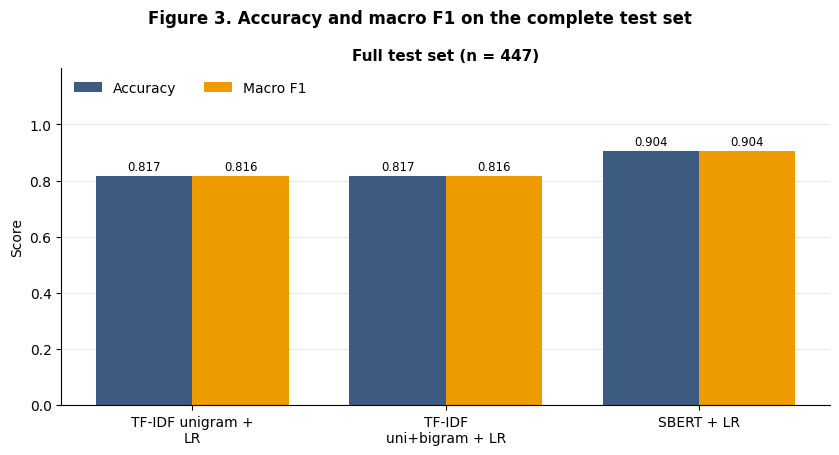

In [63]:
n_full = RESULTS[NAME_UNI]["full"]["n"]
fig, ax = plt.subplots(figsize=(8.5, 4.6))
grouped_metric_chart(ax, metrics_frame("full"), f"Full test set (n = {n_full})")
fig.suptitle("Figure 3. Accuracy and macro F1 on the complete test set", fontweight="bold")
fig.tight_layout()
save_fig(fig, "fig3_full_test_performance")

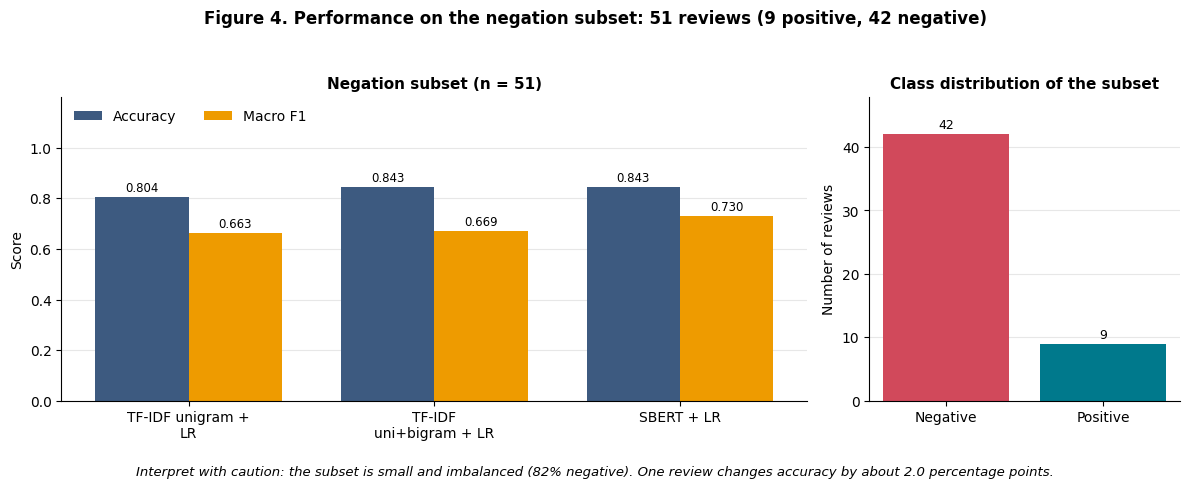

In [64]:
n_sub, pos_sub, neg_sub = class_counts(test_df[test_df["negation"]])

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.8), gridspec_kw={"width_ratios": [2.4, 1]})
grouped_metric_chart(ax1, metrics_frame("neg"), f"Negation subset (n = {n_sub})")
ax2.bar(["Negative", "Positive"], [neg_sub, pos_sub], color=[LABEL_COLORS["Negative"], LABEL_COLORS["Positive"]])
ax2.set_ylabel("Number of reviews")
ax2.set_title("Class distribution of the subset")
annotate_bars(ax2)

fig.suptitle(f"Figure 4. Performance on the negation subset: {n_sub} reviews ({pos_sub} positive, {neg_sub} negative)",
             fontweight="bold")
shape = "small and imbalanced" if abs(neg_sub / n_sub - 0.5) > 0.1 else "small"   # wording follows the actual class mix
fig.text(0.5, 0.01,
         f"Interpret with caution: the subset is {shape} ({neg_sub / n_sub:.0%} negative). "
         f"One review changes accuracy by about {100 / n_sub:.1f} percentage points.",
         ha="center", fontsize=9.5, style="italic")
fig.tight_layout(rect=(0, 0.05, 1, 0.94))
save_fig(fig, "fig4_negation_subset_performance")

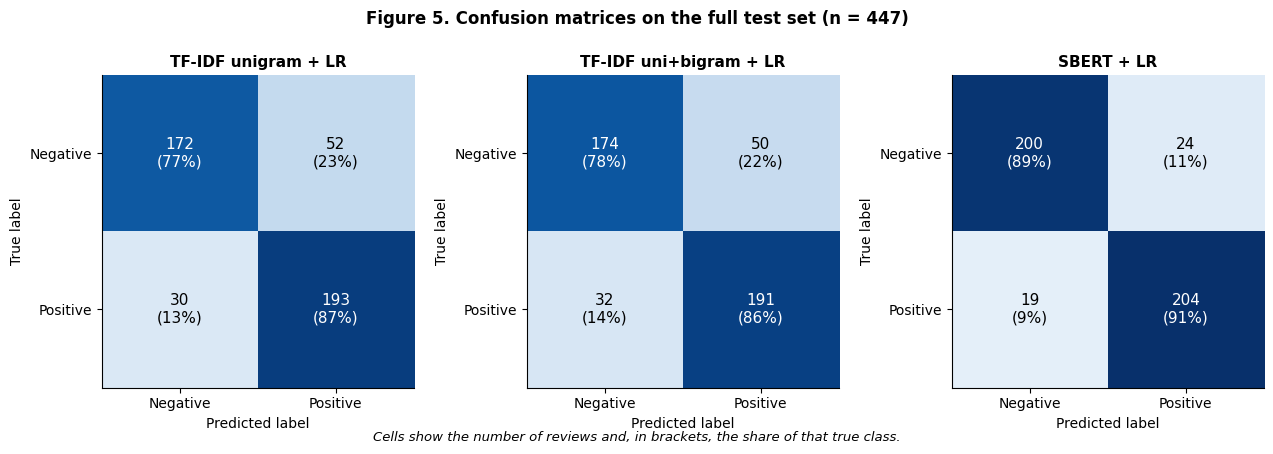

In [65]:
y_true_test = test_df["label"].to_numpy()
cms = {name: confusion_matrix(y_true_test, TEST_PREDS[name], labels=[0, 1]) for name in RESULTS}
vmax = max(cm.max() for cm in cms.values())          # same colour scale for all three models

fig, axes = plt.subplots(1, len(cms), figsize=(4.3 * len(cms), 4.4))
for ax, (name, cm) in zip(np.atleast_1d(axes), cms.items()):
    ax.imshow(cm, cmap="Blues", vmin=0, vmax=vmax)
    ax.grid(False)
    for r in range(2):
        for c in range(2):
            ax.text(c, r, f"{cm[r, c]}\n({cm[r, c] / cm[r].sum():.0%})", ha="center", va="center",
                    color="white" if cm[r, c] > vmax / 2 else "black", fontsize=11)
    ax.set_xticks([0, 1]); ax.set_xticklabels(["Negative", "Positive"])
    ax.set_yticks([0, 1]); ax.set_yticklabels(["Negative", "Positive"])
    ax.set_xlabel("Predicted label"); ax.set_ylabel("True label")
    ax.set_title(textwrap.fill(name, 22))

fig.suptitle(f"Figure 5. Confusion matrices on the full test set (n = {len(y_true_test)})", fontweight="bold")
fig.text(0.5, 0.0, "Cells show the number of reviews and, in brackets, the share of that true class.",
         ha="center", fontsize=9.5, style="italic")
fig.tight_layout(rect=(0, 0.04, 1, 0.94))
save_fig(fig, "fig5_confusion_matrices")

In [66]:
# Observed differences, computed from RESULTS (nothing typed in by hand)
def describe_scope(title, scope):
    scores = metrics_frame(scope)
    n = RESULTS[NAME_UNI][scope]["n"]
    ranking = ", ".join(f"{m} {v:.3f}" for m, v in scores["Macro F1"].sort_values(ascending=False).items())
    best_tfidf = scores.loc[[NAME_UNI, NAME_BI], "Macro F1"].idxmax()
    print(f"{title} (n = {n})")
    print(f"  Macro F1, highest to lowest: {ranking}")
    for label, a, b in ((f"{NAME_SBERT} vs {best_tfidf}", NAME_SBERT, best_tfidf), (f"{NAME_BI} vs {NAME_UNI}", NAME_BI, NAME_UNI)):
        d_f1 = 100 * (scores.loc[a, "Macro F1"] - scores.loc[b, "Macro F1"])
        d_acc = 100 * (scores.loc[a, "Accuracy"] - scores.loc[b, "Accuracy"])
        reviews = round(abs(d_acc) * n / 100)
        print(f"  {label}: macro F1 {d_f1:+.1f} pp, accuracy {d_acc:+.1f} pp (about {reviews} review{'s' if reviews != 1 else ''})")

print("OBSERVED RESULTS")
describe_scope("Full test set", "full")
print()
describe_scope("Negation subset", "neg")

OBSERVED RESULTS
Full test set (n = 447)
  Macro F1, highest to lowest: SBERT + LR 0.904, TF-IDF uni+bigram + LR 0.816, TF-IDF unigram + LR 0.816
  SBERT + LR vs TF-IDF uni+bigram + LR: macro F1 +8.8 pp, accuracy +8.7 pp (about 39 reviews)
  TF-IDF uni+bigram + LR vs TF-IDF unigram + LR: macro F1 +0.0 pp, accuracy +0.0 pp (about 0 reviews)

Negation subset (n = 51)
  Macro F1, highest to lowest: SBERT + LR 0.730, TF-IDF uni+bigram + LR 0.669, TF-IDF unigram + LR 0.663
  SBERT + LR vs TF-IDF uni+bigram + LR: macro F1 +6.1 pp, accuracy +0.0 pp (about 0 reviews)
  TF-IDF uni+bigram + LR vs TF-IDF unigram + LR: macro F1 +0.6 pp, accuracy +3.9 pp (about 2 reviews)


### Observed Results and Possible Explanations

The results above are based on our actual test predictions. The following explanations are possible interpretations and were not tested through additional experiments.

- **Sentence-BERT vs. TF-IDF:** Sentence-BERT may perform better because its pretrained encoder captures semantic similarities between words and phrases, while TF-IDF relies on word and n-gram frequencies learned from the training data.

- **Unigram vs. Bigram:** We compared both models on the same test reviews. Small differences should be interpreted cautiously, especially on the smaller negation subset, and should not be considered significant improvements.

- **Confusion Matrices:** We used confusion matrices to examine the types of errors made by each model and identify differences between positive and negative predictions.

### 5.4 Unigram vs unigram + bigram
To isolate the effect of bigrams, we compared test predictions between the two TF-IDF models and listed reviews where **adding bigrams corrected a unigram error** versus where **bigrams introduced a new error**. The evidence columns report the top three contributing features (`TF-IDF × coefficient`; `+` favors Positive, `-` favors Negative), with bigrams appearing as space-separated word pairs.

In [67]:
pred_df = test_df[["source", "text", "label", "negation", "negation_terms"]].copy()
for name, p in TEST_PREDS.items():
    pred_df[name] = p
pred_df["uni_ok"] = pred_df[NAME_UNI] == pred_df["label"]
pred_df["bi_ok"] = pred_df[NAME_BI] == pred_df["label"]

def evidence(text, model, k=3):
    """Top-k features by contribution to the model's score for this review."""
    vec, clf = model.named_steps["tfidf"], model.named_steps["clf"]
    x = vec.transform([text])
    names = vec.get_feature_names_out()
    contrib = sorted(((names[i], x[0, i] * clf.coef_[0][i]) for i in x.nonzero()[1]), key=lambda t: -abs(t[1]))
    return "; ".join(f"{n} ({c:+.2f})" for n, c in contrib[:k])

def change_table(frame):
    """Table of reviews where the unigram and bigram models differ in correctness."""
    rows = frame.assign(
        sentence=frame["text"],
        true_label=frame["label"].map(LABEL_NAMES),
        unigram_pred=frame[NAME_UNI].map(LABEL_NAMES),
        bigram_pred=frame[NAME_BI].map(LABEL_NAMES),
        unigram_evidence=frame["text"].apply(lambda t: evidence(t, MODELS[NAME_UNI])),
        bigram_evidence=frame["text"].apply(lambda t: evidence(t, MODELS[NAME_BI])),
    )
    return rows[["source", "sentence", "true_label", "unigram_pred", "bigram_pred", "unigram_evidence", "bigram_evidence"]]

scopes = {"negation subset": pred_df[pred_df["negation"]], "reviews without negation": pred_df[~pred_df["negation"]]}
changes = {}
for scope, frame in scopes.items():
    fixed = frame[~frame["uni_ok"] & frame["bi_ok"]]
    broken = frame[frame["uni_ok"] & ~frame["bi_ok"]]
    changes[scope] = (fixed, broken)
    print(f"{scope} (n={len(frame)}): bigrams corrected {len(fixed)} unigram errors and introduced {len(broken)} new errors "
          f"(net {len(fixed) - len(broken):+d}).")

fixed_neg, broken_neg = changes["negation subset"]
print("\nNEGATION SUBSET: errors corrected by adding bigrams")
display(change_table(fixed_neg) if len(fixed_neg) else "none")
print("NEGATION SUBSET: new errors introduced by adding bigrams")
display(change_table(broken_neg) if len(broken_neg) else "none")

fixed_all = pd.concat([changes[s][0] for s in changes])
broken_all = pd.concat([changes[s][1] for s in changes])
pd.concat([change_table(fixed_all).assign(change="bigram corrected unigram error"),
           change_table(broken_all).assign(change="bigram introduced new error")]
          ).to_csv(os.path.join(RESULTS_DIR, "unigram_vs_bigram_changes.csv"), index=False)

negation subset (n=51): bigrams corrected 3 unigram errors and introduced 1 new errors (net +2).
reviews without negation (n=396): bigrams corrected 18 unigram errors and introduced 20 new errors (net -2).

NEGATION SUBSET: errors corrected by adding bigrams


,source,sentence,true_label,unigram_pred,bigram_pred,unigram_evidence,bigram_evidence
46,yelp,"The Wife hated her meal (coconut shrimp), and our friends really did not enjoy their meals, either.",Negative,Positive,Negative,not (-1.28); hated (-0.49); and (+0.38),not (-1.09); and (+0.40); their (+0.22)
234,amazon,"Bluetooth does not work, phone locks up, screens just flash up and now it just makes calls randomly while in my pocket locked.",Negative,Positive,Negative,not (-1.23); up (+0.48); calls (-0.48),not (-1.00); it just (-0.40); and (+0.36)
251,yelp,This place deserves no stars.,Negative,Positive,Negative,no (-1.50); deserves (+0.99); stars (+0.78),no (-1.01); deserves (+0.62); stars (+0.43)


NEGATION SUBSET: new errors introduced by adding bigrams


,source,sentence,true_label,unigram_pred,bigram_pred,unigram_evidence,bigram_evidence
32,amazon,This is definitely a must have if your state does not allow cell phone usage while driving.,Positive,Positive,Negative,not (-1.39); definitely (+0.91); driving (+0.62),not (-1.11); definitely (+0.49); this is (+0.33)


On the negation subset (`n=51`), adding bigrams corrected 3 unigram errors (e.g., *"really did not enjoy"*, *"does not work"*, *"deserves no stars"*) and introduced 1 new error (`net +2`), whereas on non-negation reviews (`n=396`) the net change was `-2` (18 corrected vs. 20 introduced). Notably, even when bigrams corrected a negation error, single negation unigrams (`not`, `no`) remained among the strongest negative contributors, while bigrams shifted surrounding feature weights enough to flip the prediction.

#### Effect of adding bigrams: summary chart
Figure 6 summarizes the error shifts across the negation subset and non-negation reviews, showing unigram errors **corrected** by bigrams (green) versus **new errors** introduced (red).

,Corrected by bigrams,New errors from bigrams,Net change
Group of reviews,,,
negation subset\n(n = 51),3,1,2
reviews without negation\n(n = 396),18,20,-2


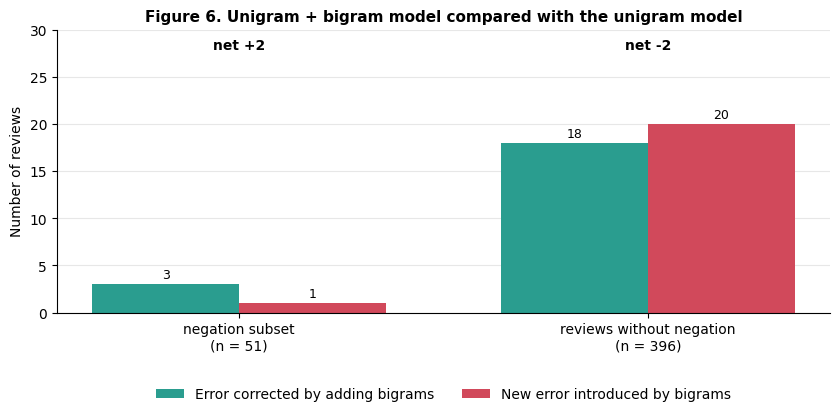

In [68]:
rows = []
for scope_name, (fixed_part, broken_part) in changes.items():
    rows.append({"scope": f"{scope_name}\n(n = {len(scopes[scope_name])})",
                 "Corrected by bigrams": len(fixed_part), "New errors from bigrams": len(broken_part)})
change_counts = pd.DataFrame(rows).set_index("scope")
change_counts["Net change"] = change_counts["Corrected by bigrams"] - change_counts["New errors from bigrams"]
display(change_counts.rename_axis("Group of reviews"))

fig, ax = plt.subplots(figsize=(8.5, 4.4))
x, width = np.arange(len(change_counts)), 0.36
ax.bar(x - width / 2, change_counts["Corrected by bigrams"], width, color="#2a9d8f", label="Error corrected by adding bigrams")
ax.bar(x + width / 2, change_counts["New errors from bigrams"], width, color="#d1495b", label="New error introduced by bigrams")
ax.set_xticks(x)
ax.set_xticklabels(change_counts.index)
ax.set_ylabel("Number of reviews")
ax.yaxis.get_major_locator().set_params(integer=True)
annotate_bars(ax)
top = max(3, change_counts[["Corrected by bigrams", "New errors from bigrams"]].to_numpy().max() * 1.5)
ax.set_ylim(0, top)                                  # headroom so labels never collide, even for tiny counts
for xi, net in zip(x, change_counts["Net change"]):
    ax.text(xi, top * 0.97, f"net {net:+d}", ha="center", va="top", fontsize=10, fontweight="bold")
ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.22), ncol=2)
ax.set_title("Figure 6. Unigram + bigram model compared with the unigram model", fontweight="bold")
fig.tight_layout()
save_fig(fig, "fig6_bigram_corrections_vs_new_errors")

Each bar counts reviews where the two TF-IDF models differ in correctness, with net gain defined as *corrected minus new errors*. Because the counts are small—especially on the negation subset—a single review can shift the net balance, so we interpret these totals alongside the specific examples above.

In [69]:
# How the models weight negation words and negation bigrams (learned from the training data)
vec_b, clf_b = MODELS[NAME_BI].named_steps["tfidf"], MODELS[NAME_BI].named_steps["clf"]
vec_u, clf_u = MODELS[NAME_UNI].named_steps["tfidf"], MODELS[NAME_UNI].named_steps["clf"]

print("Unigram weights of the negation words (positive = towards Positive):")
for w in NEGATION_TERMS:
    row = [f"unigram model: {clf_u.coef_[0][vec_u.vocabulary_[w]]:+.2f}" if w in vec_u.vocabulary_ else "unigram model: not in vocabulary"]
    row.append(f"bigram model: {clf_b.coef_[0][vec_b.vocabulary_[w]]:+.2f}" if w in vec_b.vocabulary_ else "bigram model: not in vocabulary")
    print(f"  {w:<6}", " | ".join(row))

names_b = vec_b.get_feature_names_out()
doc_freq = np.asarray((vec_b.transform(train_df["text"]) > 0).sum(axis=0)).ravel()
neg_set = set(NEGATION_TERMS)
bigram_rows = [(n, clf_b.coef_[0][i], int(doc_freq[i])) for i, n in enumerate(names_b)
               if " " in n and neg_set & set(n.split()) and doc_freq[i] >= 2]
bigram_table = (pd.DataFrame(bigram_rows, columns=["negation bigram", "coefficient", "training reviews containing it"])
                .assign(abs_coef=lambda t: t["coefficient"].abs()).sort_values("abs_coef", ascending=False)
                .drop(columns="abs_coef").head(15).round(2).reset_index(drop=True))
print("\nNegation bigrams (seen in at least 2 training reviews) with the largest weights in the bigram model:")
display(bigram_table)

all_bigrams = int((np.array([" " in n for n in names_b])).sum())
rare = int(((np.array([" " in n for n in names_b])) & (doc_freq == 1)).sum())
print(f"\nThe bigram vocabulary has {all_bigrams} bigrams; {rare} of them appear in only one training review.")

Unigram weights of the negation words (positive = towards Positive):
  not    unigram model: -8.86 | bigram model: -9.32
  never  unigram model: -3.52 | bigram model: -2.51
  no     unigram model: -3.78 | bigram model: -3.25

Negation bigrams (seen in at least 2 training reviews) with the largest weights in the bigram model:


,negation bigram,coefficient,training reviews containing it
0,not good,-3.58,11
1,no complaints,2.06,2
2,will never,-2.04,7
3,would not,-1.70,9
4,has no,-1.64,3
5,not worth,-1.38,4
6,not the,-1.32,2
7,are not,-1.32,6
8,not work,-1.24,7
9,its not,-1.22,3



The bigram vocabulary has 14966 bigrams; 12690 of them appear in only one training review.


Negation words remain strongly negative across both models (`not` at `-8.86` vs. `-9.32`, `never` at `-3.52` vs. `-2.51`, `no` at `-3.78` vs. `-3.25`). Most top negation bigrams carry negative weights (such as *"not good"*, *"will never"*, and *"would not"*), while exceptions such as *"no complaints"* (`+2.06`) point positive[cite: 4]. Out of `14,966` bigrams in the vocabulary, `12,690` appear in only one training review, limiting how reliably rare bigrams generalize[cite: 4].

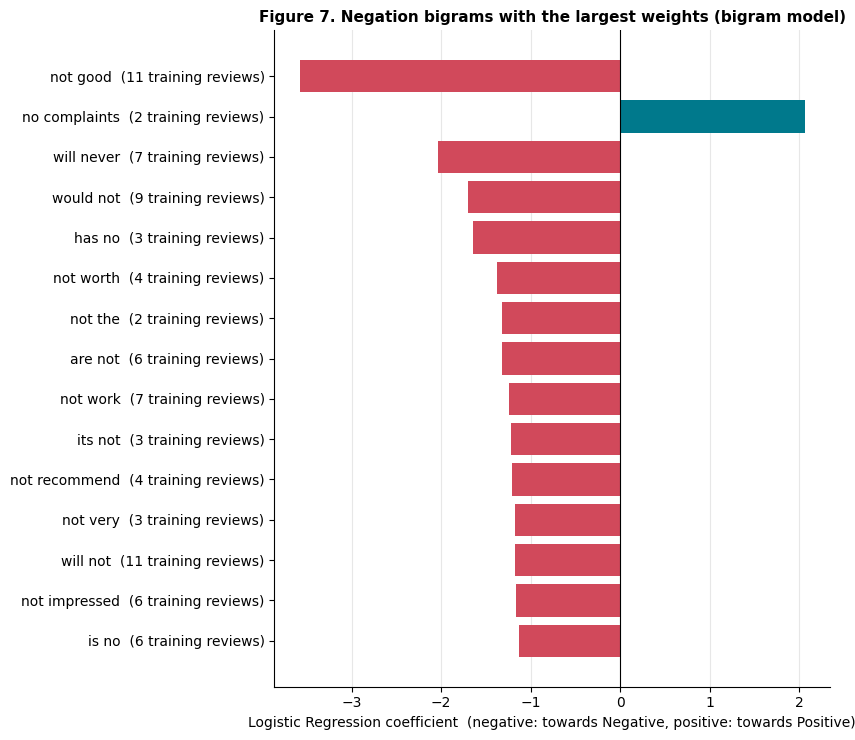

Example phrases:
  "not good": bigram weight -3.58, appears in 11 training reviews
  "not bad": bigram weight +1.13, appears in 1 training reviews
  "no good": not in the bigram vocabulary (does not occur in the training data)
Unigram model weights of the single words: "not" -8.86, "good" +6.07


In [70]:
# Weights of negation bigrams and of the words inside "not good" (from the already trained models)
if len(bigram_table):
    shown = bigram_table.iloc[::-1]
    fig, ax = plt.subplots(figsize=(8.5, 0.38 * len(shown) + 1.8))
    ax.barh([f"{b}  ({int(f)} training reviews)" for b, f in zip(shown["negation bigram"], shown["training reviews containing it"])],
            shown["coefficient"],
            color=[LABEL_COLORS["Positive"] if c > 0 else LABEL_COLORS["Negative"] for c in shown["coefficient"]])
    ax.axvline(0, color="black", linewidth=0.8)
    ax.set_xlabel("Logistic Regression coefficient  (negative: towards Negative, positive: towards Positive)")
    ax.grid(axis="y", visible=False); ax.grid(axis="x", alpha=0.3)
    ax.set_title("Figure 7. Negation bigrams with the largest weights (bigram model)", fontweight="bold")
    fig.tight_layout()
    save_fig(fig, "fig7_negation_bigram_weights")

print("Example phrases:")
for phrase in ["not good", "not bad", "no good"]:
    if phrase in vec_b.vocabulary_:
        j = vec_b.vocabulary_[phrase]
        print(f'  "{phrase}": bigram weight {clf_b.coef_[0][j]:+.2f}, appears in {int(doc_freq[j])} training reviews')
    else:
        print(f'  "{phrase}": not in the bigram vocabulary (does not occur in the training data)')
parts = [f'"{w}" {clf_u.coef_[0][vec_u.vocabulary_[w]]:+.2f}' for w in ("not", "good") if w in vec_u.vocabulary_]
print("Unigram model weights of the single words: " + ", ".join(parts))


The unigram model treats words such as *not* and *good* as separate features, while the bigram model adds a separate feature for the phrase *not good*, which can capture its negative meaning.

However, this depends on how often the phrase appears in the training data. Since many bigrams occur only once, they may add noise instead of improving performance.

We used the corrected and new errors, phrase frequencies, and bigram weights to interpret the results. Any improvement was treated as tentative because the negation subset was small.

### 5.5 Error analysis
We list all misclassified test reviews per model with the sentence, true label, predicted label, and model name. The `tags` column provides lightweight automatic hints (such as negation terms, contrast words like *but*, or very short reviews) rather than a diagnosis, so we analyze the selected errors in the report.

In [71]:
def error_tags(text):
    tags = []
    terms = matched_terms(text)
    if terms:
        tags.append("negation: " + ", ".join(terms))
    if re.search(r"\b(but|however|although|though|yet)\b", text, re.IGNORECASE):
        tags.append("contrast word")
    if len(text.split()) <= 5:
        tags.append("very short")
    return "; ".join(tags) if tags else "-"

records = []
y_test = test_df["label"].to_numpy()
for name, preds in TEST_PREDS.items():
    for i in np.where(preds != y_test)[0]:
        r = test_df.iloc[i]
        records.append({"model": name, "source": r["source"], "negation": bool(r["negation"]), "sentence": r["text"],
                        "true_label": LABEL_NAMES[int(r["label"])], "predicted_label": LABEL_NAMES[int(preds[i])],
                        "tags": error_tags(r["text"]), "test_index": int(i)})
errors_df = pd.DataFrame(records)
errors_df["wrong_in_n_models"] = errors_df.groupby("test_index")["model"].transform("count")
errors_df.drop(columns="test_index").to_csv(os.path.join(RESULTS_DIR, "error_analysis.csv"), index=False)

summary = (errors_df.groupby(["model", "negation"]).size().unstack(fill_value=0)
           .rename(columns={False: "errors without negation", True: "errors with negation"}))
summary["total errors"] = summary.sum(axis=1)
print("Number of misclassified test reviews per model:")
display(summary.reindex([NAME_UNI, NAME_BI, NAME_SBERT]))

cols = ["model", "source", "sentence", "true_label", "predicted_label", "wrong_in_n_models", "tags"]
for name in (NAME_UNI, NAME_BI, NAME_SBERT):
    sub = errors_df[(errors_df["model"] == name) & errors_df["negation"]]
    print(f"\n{name}: {len(sub)} misclassified reviews that contain negation")
    display(sub[cols].reset_index(drop=True))

shared = errors_df[(errors_df["wrong_in_n_models"] == 3) & errors_df["negation"]].drop_duplicates("test_index")
print(f"\nNegation reviews misclassified by all three models: {len(shared)}")
display(shared[["source", "sentence", "true_label", "tags"]].reset_index(drop=True))

print("\nMost common tags among negation errors (all models):")
print(errors_df[errors_df["negation"]]["tags"].str.split("; ").explode().str.replace(r"negation: .*", "negation term", regex=True)
      .value_counts().to_string())

Number of misclassified test reviews per model:


negation,errors without negation,errors with negation,total errors
model,,,
TF-IDF unigram + LR,72,10,82
TF-IDF uni+bigram + LR,74,8,82
SBERT + LR,35,8,43



TF-IDF unigram + LR: 10 misclassified reviews that contain negation


,model,source,sentence,true_label,predicted_label,wrong_in_n_models,tags
0,TF-IDF unigram + LR,yelp,"The Wife hated her meal (coconut shrimp), and our friends really did not enjoy their meals, either.",Negative,Positive,1,negation: not
1,TF-IDF unigram + LR,imdb,I will never forget it now.,Positive,Negative,2,negation: never
2,TF-IDF unigram + LR,amazon,Makes it easier to keep up with my bluetooth when I'm not wearing it.,Negative,Positive,2,negation: not
3,TF-IDF unigram + LR,yelp,"The wontons were thin, not thick and chewy, almost melt in your mouth.",Positive,Negative,3,negation: not
4,TF-IDF unigram + LR,imdb,The movie is not completely perfect but 'Titta Di Girolamo' will stay with you for a long time after the vision of the movie.,Positive,Negative,2,negation: not; contrast word
5,TF-IDF unigram + LR,amazon,"Bluetooth does not work, phone locks up, screens just flash up and now it just makes calls randomly while in my pocket locked.",Negative,Positive,1,negation: not
6,TF-IDF unigram + LR,yelp,This place deserves no stars.,Negative,Positive,1,negation: no; very short
7,TF-IDF unigram + LR,yelp,The tables outside are also dirty a lot of the time and the workers are not always friendly and helpful with the menu.,Negative,Positive,2,negation: not
8,TF-IDF unigram + LR,amazon,"No shifting, no bubbling, no peeling, not even a scratch, NOTHING!I couldn't be more happier with my new one for the Droid.",Positive,Negative,2,"negation: no, not"
9,TF-IDF unigram + LR,imdb,Enough can not be said of the remarkable animation in this film.,Positive,Negative,3,negation: not



TF-IDF uni+bigram + LR: 8 misclassified reviews that contain negation


,model,source,sentence,true_label,predicted_label,wrong_in_n_models,tags
0,TF-IDF uni+bigram + LR,amazon,This is definitely a must have if your state does not allow cell phone usage while driving.,Positive,Negative,2,negation: not
1,TF-IDF uni+bigram + LR,imdb,I will never forget it now.,Positive,Negative,2,negation: never
2,TF-IDF uni+bigram + LR,amazon,Makes it easier to keep up with my bluetooth when I'm not wearing it.,Negative,Positive,2,negation: not
3,TF-IDF uni+bigram + LR,yelp,"The wontons were thin, not thick and chewy, almost melt in your mouth.",Positive,Negative,3,negation: not
4,TF-IDF uni+bigram + LR,imdb,The movie is not completely perfect but 'Titta Di Girolamo' will stay with you for a long time after the vision of the movie.,Positive,Negative,2,negation: not; contrast word
5,TF-IDF uni+bigram + LR,yelp,The tables outside are also dirty a lot of the time and the workers are not always friendly and helpful with the menu.,Negative,Positive,2,negation: not
6,TF-IDF uni+bigram + LR,amazon,"No shifting, no bubbling, no peeling, not even a scratch, NOTHING!I couldn't be more happier with my new one for the Droid.",Positive,Negative,2,"negation: no, not"
7,TF-IDF uni+bigram + LR,imdb,Enough can not be said of the remarkable animation in this film.,Positive,Negative,3,negation: not



SBERT + LR: 8 misclassified reviews that contain negation


,model,source,sentence,true_label,predicted_label,wrong_in_n_models,tags
0,SBERT + LR,imdb,"This was reflected not only in the cast, but also in the below-par script, which borrowed much from the earlier classic.",Negative,Positive,1,negation: not; contrast word
1,SBERT + LR,amazon,This is definitely a must have if your state does not allow cell phone usage while driving.,Positive,Negative,2,negation: not
2,SBERT + LR,amazon,The case is a flimsy piece of plastic and has no front or side protection whatsoever.,Negative,Positive,1,negation: no
3,SBERT + LR,amazon,Also the area where my unit broke).- I'm not too fond of the magnetic strap.,Negative,Positive,1,negation: not
4,SBERT + LR,yelp,"The wontons were thin, not thick and chewy, almost melt in your mouth.",Positive,Negative,3,negation: not
5,SBERT + LR,yelp,My drink was never empty and he made some really great menu suggestions.,Positive,Negative,1,negation: never
6,SBERT + LR,imdb,"Not only did it only confirm that the film would be unfunny and generic, but it also managed to give away the ENTIRE movie; and I'm not exaggerating - every...",Negative,Positive,1,negation: not; contrast word
7,SBERT + LR,imdb,Enough can not be said of the remarkable animation in this film.,Positive,Negative,3,negation: not



Negation reviews misclassified by all three models: 2


,source,sentence,true_label,tags
0,yelp,"The wontons were thin, not thick and chewy, almost melt in your mouth.",Positive,negation: not
1,imdb,Enough can not be said of the remarkable animation in this film.,Positive,negation: not



Most common tags among negation errors (all models):
tags
negation term    26
contrast word     4
very short        1


#### Error summary chart
Figure 8 summarizes the error tables across models by showing misclassified test review counts on the left and **error rates** on the right to account for differing group sizes across negation and non-negation reviews.

Errors (count)                  Error rate (%)                 
                        With negation Without negation  With negation Without negation
model                                                                                 
TF-IDF unigram + LR                10               72           19.6             18.2
TF-IDF uni+bigram + LR              8               74           15.7             18.7
SBERT + LR                          8               35           15.7              8.8

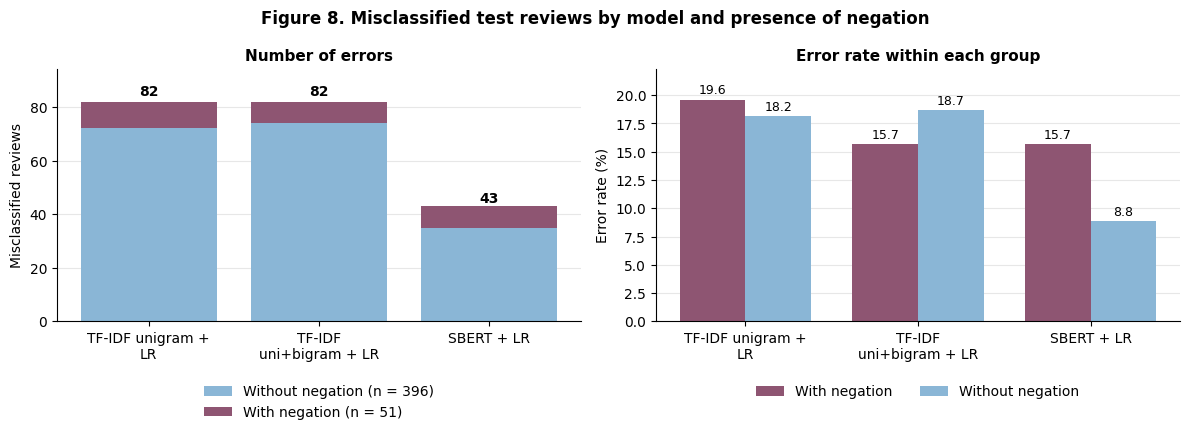

In [72]:
model_order = list(RESULTS)
n_with = int(test_df["negation"].sum())
n_without = len(test_df) - n_with
err = errors_df.groupby(["model", "negation"]).size().unstack(fill_value=0).reindex(model_order, fill_value=0)
for flag in (True, False):
    if flag not in err.columns:
        err[flag] = 0
err = pd.DataFrame({"With negation": err[True], "Without negation": err[False]})
rates = pd.DataFrame({"With negation": err["With negation"] / n_with * 100,
                      "Without negation": err["Without negation"] / n_without * 100})
display(pd.concat({"Errors (count)": err, "Error rate (%)": rates.round(1)}, axis=1))

group_colors = {"With negation": "#8e5572", "Without negation": "#8ab6d6"}
short_names = [textwrap.fill(m, 16) for m in model_order]
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.6))

ax1.bar(short_names, err["Without negation"], color=group_colors["Without negation"], label=f"Without negation (n = {n_without})")
ax1.bar(short_names, err["With negation"], bottom=err["Without negation"], color=group_colors["With negation"], label=f"With negation (n = {n_with})")
for k, m in enumerate(model_order):
    ax1.text(k, err.loc[m].sum() * 1.02 + 0.5, int(err.loc[m].sum()), ha="center", fontweight="bold")
ax1.set_ylabel("Misclassified reviews"); ax1.set_title("Number of errors"); ax1.margins(y=0.15)
ax1.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=1)

x, width = np.arange(len(model_order)), 0.38
for offset, grp in zip((-width / 2, width / 2), ("With negation", "Without negation")):
    ax2.bar(x + offset, rates[grp], width, color=group_colors[grp], label=grp)
ax2.set_xticks(x); ax2.set_xticklabels(short_names)
ax2.set_ylabel("Error rate (%)"); ax2.set_title("Error rate within each group")
annotate_bars(ax2, fmt="{:.1f}")
ax2.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=2)

fig.suptitle("Figure 8. Misclassified test reviews by model and presence of negation", fontweight="bold")
fig.tight_layout()
save_fig(fig, "fig8_errors_by_model_and_negation")

In the right panel, higher bars indicate higher error rates within each review group. While negation can flip nearby word polarity and complicate classification, reviews with and without negation also differ in length, source, and phrasing, so we treat any polarity-reversal explanation cautiously rather than as a proven cause.

## 6. Try it
Enter a review to get a sentiment prediction from any of the three trained models without retraining (`no retraining happens here`), or submit empty input to see a prompt message.

In [73]:
def predict_review(text, model_name=NAME_BI):
    """Predict Positive/Negative for a new review with an already trained model."""
    if text is None or not str(text).strip():
        print("Please enter a review, for example: 'The food was excellent'.")
        return None
    if model_name not in MODELS:
        print(f"Model '{model_name}' is not available. Choose one of: {list(MODELS)}")
        return None
    model = MODELS[model_name]
    label = int(model.predict([text])[0])
    msg = f"[{model_name}] {LABEL_NAMES[label]}"
    if hasattr(model, "predict_proba"):
        msg += f" (confidence {float(np.max(model.predict_proba([text])[0])):.0%})"
    print(f"{msg} | {text!r}")
    return LABEL_NAMES[label]

for example in ["The food was excellent", "The food was not good", "The service was not bad at all", ""]:
    for model_name in MODELS:
        predict_review(example, model_name)
    print()

# Interactive version:
# predict_review(input("Enter a review: "))

[TF-IDF unigram + LR] Positive (confidence 93%) | 'The food was excellent'
[TF-IDF uni+bigram + LR] Positive (confidence 83%) | 'The food was excellent'
[SBERT + LR] Positive (confidence 100%) | 'The food was excellent'

[TF-IDF unigram + LR] Negative (confidence 90%) | 'The food was not good'
[TF-IDF uni+bigram + LR] Negative (confidence 95%) | 'The food was not good'
[SBERT + LR] Negative (confidence 100%) | 'The food was not good'

[TF-IDF unigram + LR] Negative (confidence 100%) | 'The service was not bad at all'
[TF-IDF uni+bigram + LR] Negative (confidence 99%) | 'The service was not bad at all'
[SBERT + LR] Negative (confidence 98%) | 'The service was not bad at all'

Please enter a review, for example: 'The food was excellent'.
Please enter a review, for example: 'The food was excellent'.
Please enter a review, for example: 'The food was excellent'.



### Members' original labelled examples
Each team member contributes **two original reviews** along with expected labels (`1` = Positive, `0` = Negative), displayed separately outside the test set and prior evaluation metrics.

In [74]:
ORIGINAL_EXAMPLES = [
    # (member, review written by the member, label)
    ("Joud", "The service was not bad at all.", 1),
    ("Joud","i did not enjoy the movie.",0),

]

if ORIGINAL_EXAMPLES:
    orig_df = pd.DataFrame(ORIGINAL_EXAMPLES, columns=["member", "text", "label"])
    for name, model in MODELS.items():
        orig_df[name] = [LABEL_NAMES[int(p)] for p in model.predict(orig_df["text"].tolist())]
    orig_df["true label"] = orig_df["label"].map(LABEL_NAMES)
    display(orig_df.drop(columns="label"))
else:
    print("No original examples entered yet: each member adds two reviews to ORIGINAL_EXAMPLES above.")

,member,text,TF-IDF unigram + LR,TF-IDF uni+bigram + LR,SBERT + LR,true label
0,Joud,The service was not bad at all.,Negative,Negative,Negative,Positive
1,Joud,i did not enjoy the movie.,Negative,Negative,Negative,Negative


## 7. Sources
**Data**
- D. Kotzias, M. Denil, N. de Freitas and P. Smyth, "From Group to Individual Labels using Deep Features," KDD 2015. UCI Sentiment Labelled Sentences dataset: https://archive.ics.uci.edu/dataset/331/sentiment+labelled+sentences

**Libraries and pretrained weights**
- scikit-learn (TfidfVectorizer, LogisticRegression, train_test_split, metrics), pandas, NumPy
- sentence-transformers library and the pretrained `sentence-transformers/all-MiniLM-L6-v2` model (N. Reimers and I. Gurevych, "Sentence-BERT: Sentence Embeddings using Siamese BERT-Networks," EMNLP 2019)

**Related work cited in the proposal**
- [1] D. B. Shanto, M. Yadav, P. Panth and S. C. Satapathy, "From TF-IDF to Transformers: A Comparative and Ensemble Approach to Sentiment Classification," IC-ICNS 2026.
- [2] A. Khandelwal and S. Sawant, "NegBERT: A Transfer Learning Approach for Negation Detection and Scope Resolution," LREC 2020.

### AI Assistance Disclosure
We used AI tools strictly as supportive assistants rather than automated authors; all experimental decisions, verification, and final writing were carried out by the team:
* **Claude:** Assisted with debugging code issues, structuring the report outline, and aligning code outputs with the written sections.
* **ChatGPT:** Helped us explore and interpret deeper patterns in the evaluation results and error analysis.
* **Gemini:** Assisted in organizing, refining, and standardizing the Jupyter Notebook markdown documentation for clarity and consistency.